# ECON 5200 Final Project: Consulting Report

**A causal question a client would pay to have answered, a design you can defend under attack, a tool that lets them
explore counterfactuals, and a recommendation with its uncertainty attached.**

This notebook is the spine of the project. Each milestone hands in part of it:

| Hand-in | Due | Parts |
|---|---|---|
| Milestone 1: Proposal + EDA (10 pts) | Mon 23 Nov | Part 2, plus the two-page proposal from the **Proposal Template (Word)** |
| Milestone 2: Analysis + Threats (20 pts) | Thu 3 Dec | Part 3, a first draft of Part 4, a Part 5 prototype with one working what-if input |
| Final Project (70 pts) | see Canvas | all of it, with Part 1 written last |

Every number in your report must be printed by a cell in this notebook. If the code does not print it, the report
cannot use it.

---

## Part 0: Setup

In [1]:
# Colab has pandas, numpy, statsmodels, scikit-learn and matplotlib already.
# Install only what your design needs, then restart the runtime once:
# !pip -q install linearmodels        # IV (2SLS) and panel fixed effects
# !pip -q install rdrobust rddensity   # RD
# !pip -q install doubleml             # DML

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

RANDOM_STATE = 42                    # every split, fold and bootstrap uses this seed
rng = np.random.default_rng(RANDOM_STATE)
plt.rcParams["figure.figsize"] = (9, 5)
print("Setup complete.")

Setup complete.


---
## Part 1: Executive Summary

Write this **last**. Situation, Complication, Resolution, then the recommendation with its interval and the
assumption it rests on. The rubric looks for all three in the summary itself.

> **We estimate that [treatment] changes [outcome] by [X] [units] (95% CI [a, b]).**
>
> **Situation:** ___
> **Complication:** ___
> **Resolution:** ___
>
> **We recommend [action] because [reason]. At the bottom of the interval, [what the client should still do].**
>
> **The assumption that would overturn this:** ___

---
## Part 2: The Decision, the Design, and the Data (Milestone 1)

### Research design

These lines are the proposal's page 1. The **Proposal Template (Word)** on Canvas has the same headings.

- **Client and decision:** The city of Philadelphia on deciding whether to keep or change the sweetened beverage tax of 1.5 cents per ounce that they instated in January 2017.
- **Decides it:** I think a 10% fall in overall sale of sweetened beverages relative to other comprable metros would be a good measure. If there is more than a 10% decline in sales volume that means the tax is causing people to buy less meaning that the tax is working. If there is less than a 10% change in volume that means there is a profit but no major change for healthier beverage choices.
- **Causal question:** does Philadelphia's sweetened beverage tax reduce the amount of these beverages that are bought in Philadelphia and by how much?
- **Why prediction is not enough:** The model cannot tell us the exact results from the tax. Soda drinking was already falling in the years prior to 2017 so just looking at Philadelphia would be bias. To get a stronger comparison, I need to compare Philadelphia to the patterns of other metros over the same time frame.
- **Design and estimand:**
Difference in Differences, will show the effect of the tax on Philadelphia (treated) before and after the tax. The control will be how beverage sales changed in a comprable metro area without the tax, pre and post 2017.
- **Who is treated:** Phildelphia metro will be the treated group after January 2017 (when the tax was placed). There is 60 months of data before the tax and 12 months of data afterwards, broken down by each month. I plan to use a permutation test to account for the small treatment sample size.
- **The comparison:** The comparison will be against some of the other 8 metros that do not have a beverage tax in the datset such as Atlanta, Boston, Dallas, Detriot, Houston, LA, Miami and New York.
- **Key assumption:** The key assumption is parrallel trends. If the tax was not placed, the volume of sales and prices in Philadelphia would have followed the same movement and pattern as the other metros.
- **How you will check it:** I will check it with a study over the 60 months before the tax was imposed to see if philadelphia and the other metros moved together. I will also test the tax on other untaxed categories in the beverage section such as water and milk drinks, expecting to find no effect. And I will test to see if the results from Philadelphia stand out in comparison to the other metros if they in theory were to also get the tax.
- **The threat you worry about most:** The dataset I found uses the entire metro area including some surrounding suburbs however, the tax is only within city limits. The suburban sales could cover the effect and the customers could also just go to a store right outside the city. These could both push the estiamte toward zero.

In [4]:
# --- Load the data ---
# df = pd.read_csv("data/your_data.csv")      # or a download URL, so the repo reproduces without the file
import os
import urllib.request
DATA_PATH = "data/FMAP.xlsx"
URL = "https://www.ers.usda.gov/media/5399/food-at-home-monthly-area-prices-2012-to-2018.xlsx?v=69871"
if not os.path.exists(DATA_PATH):
    os.makedirs("data", exist_ok=True)
    req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as resp, open(DATA_PATH, "wb") as f:
        f.write(resp.read())

df = pd.read_excel(DATA_PATH, sheet_name="Data")
print(df.shape)
df.head()

(113400, 15)


,Year,Month,EFPG_name,EFPG_code,Metroregion_name,Metroregion_code,Purchase_dollars_wtd,Purchase_grams_wtd,Purchase_dollars_unwtd,Purchase_grams_unwtd,Number_stores,Unit_value_mean_wtd,Unit_value_se_wtd,Unit_value_mean_unwtd,Price_index_GEKS
0,2012,1,Whole-grain breads,10000,National,0,249373447,48751953624,162985218,32175581169,41781,0.512,0.0008,0.507,0.950689
1,2012,2,Whole-grain breads,10000,National,0,221806717,43031809219,151271986,29580905685,41713,0.515,0.0006,0.511,0.957493
2,2012,3,Whole-grain breads,10000,National,0,228860452,44163705148,159316789,30972313780,41717,0.518,0.0006,0.514,0.959520
3,2012,4,Whole-grain breads,10000,National,0,222272932,43511461126,154210561,30313913114,41866,0.511,0.0006,0.509,0.946289
4,2012,5,Whole-grain breads,10000,National,0,229869147,44876926984,159388752,31370959539,41708,0.512,0.0006,0.508,0.944415


In [11]:
# --- Missing values and the sample rule ---
print(df.isna().sum().sort_values(ascending=False).head(10))
# Write down every row you drop and why: the report's sample rule comes from this cell.
df["month_start"] = pd.to_datetime(dict(year=df["Year"], month=df["Month"], day=1))
df["metro"] = df["Metroregion_name"].str.split("-").str[0]

# Rule 1: Delete the agregated observations (National, Regions)
metros = df[df["Metroregion_code"] >= 10000].copy()
print(f"Rule 1: dropped {len(df) - len(metros):,} national and regional rows, kept {len(metros):,}")

# Rule 2: Drop chicago because it also did a beverage tax during this time frame.
n_before = len(metros)
metros = metros[metros["metro"] != "Chicago"]
print(f"Rule 2: dropped {n_before - len(metros):,} Chicago rows")

# Rule 3: there were huge increases in store count in 2018 so cut out that data so it doesn't skew the volume
# divide the jan store count by december to weight the data to avoid the skew
dec_to_jan = metros[metros["EFPG_code"] == 72040].pivot(index="month_start", columns="metro", values="Number_stores")
ratio = (dec_to_jan.shift(-1) / dec_to_jan).loc[[f"{y}-12-01" for y in range(2012, 2018)]]
ratio.index = [d.year + 1 for d in ratio.index]
print("\nNumber of stores, January divided by the previous December (one food group):")
print(ratio.round(2).to_string())

# set time frames- pre and post tax
START, END = pd.Timestamp("2012-01-01"), pd.Timestamp("2017-12-01")
TREAT_DATE = pd.Timestamp("2017-01-01")        # tax in force from January 1, 2017
n_before = len(metros)
metros = metros[(metros["month_start"] >= START) & (metros["month_start"] <= END)]
print(f"\nRule 3: dropped {n_before - len(metros):,} rows after December 2017")

# Build the metro-by-month panel. combine the taxed beverages into one
TAXED = [72000, 72030, 72040]
taxed = metros[metros["EFPG_code"].isin(TAXED)].copy()
taxed["share"] = taxed["Purchase_dollars_wtd"] / taxed.groupby(["metro", "month_start"])["Purchase_dollars_wtd"].transform("sum")
taxed["w_log_idx"] = taxed["share"] * np.log(taxed["Price_index_GEKS"])

g = taxed.groupby(["metro", "month_start"])
panel = pd.DataFrame({
    "log_grams": np.log(g["Purchase_grams_wtd"].sum()),
    "log_price": g["w_log_idx"].sum(),
    "stores": g["Number_stores"].mean(),
}).reset_index()
for code, name in [(72060, "log_water_grams"), (72020, "log_milk_drinks_grams")]:
    s = metros[metros["EFPG_code"] == code].set_index(["metro", "month_start"])["Purchase_grams_wtd"]
    panel = panel.merge(np.log(s).rename(name).reset_index(), on=["metro", "month_start"])

panel["treated"] = (panel["metro"] == "Philadelphia").astype(int)
panel["post"] = (panel["month_start"] >= TREAT_DATE).astype(int)

#cleaned dataset name
panel_df = panel

print(f"\nAnalysis sample: {panel_df['metro'].nunique()} metros x {panel_df['month_start'].nunique()} months = {len(panel_df)} rows")
print("Treated metro:", panel_df.loc[panel_df.treated == 1, "metro"].unique()[0], "| comparison metros:", sorted(panel_df.loc[panel_df.treated == 0, "metro"].unique()))
print("Pre-period months:", panel_df.loc[panel_df.post == 0, "month_start"].nunique(), "| post-period months:", panel_df.loc[panel_df.post == 1, "month_start"].nunique())

Year                      0
Month                     0
EFPG_name                 0
EFPG_code                 0
Metroregion_name          0
Metroregion_code          0
Purchase_dollars_wtd      0
Purchase_grams_wtd        0
Purchase_dollars_unwtd    0
Purchase_grams_unwtd      0
dtype: int64
Rule 1: dropped 37,800 national and regional rows, kept 75,600
Rule 2: dropped 7,560 Chicago rows

Number of stores, January divided by the previous December (one food group):
metro  Atlanta  Boston  Dallas  Detroit  Houston  Los Angeles  Miami  New York  Philadelphia
2013      0.91    0.98    0.96     0.93     0.96         0.94   0.97      0.96          0.97
2014      1.05    1.00    1.08     1.04     1.08         1.01   1.03      1.01          1.00
2015      1.08    1.02    1.11     1.01     1.21         1.05   0.96      1.02          1.02
2016      1.01    1.03    1.03     1.00     1.03         1.00   1.09      0.96          0.96
2017      0.87    0.95    0.87     0.82     0.86         0.99   0.

In [16]:
def balance_table(data, group, cols):
    """Means by group, the difference, and the standardised difference (difference / pooled SD).

    group: a 0/1 column. For RD pass the rows inside your bandwidth, grouped by side of the cutoff;
    for DiD, the pre-period rows grouped by treated state; for IV, grouped by the instrument.
    A standardised difference above about 0.1 in absolute value is worth a sentence in the proposal.
    """
    g1, g0 = data[data[group] == 1], data[data[group] == 0]
    rows = []
    for c in cols:
        sd = np.sqrt((g1[c].var() + g0[c].var()) / 2)
        rows.append({"variable": c, "treated": g1[c].mean(), "comparison": g0[c].mean(),
                     "difference": g1[c].mean() - g0[c].mean(),
                     "std. difference": (g1[c].mean() - g0[c].mean()) / sd if sd > 0 else np.nan})
    out = pd.DataFrame(rows).set_index("variable")
    out.loc["N"] = [len(g1), len(g0), np.nan, np.nan]
    return out.round(3)

# Table 1: pre and post tax between philadelphia and the other 8 metros
pre = panel_df[panel_df["post"] == 0]
print("Table 1. pre and post tax between philadelphia and the other 8 metros")
table1 = balance_table(pre, "treated", ["log_grams", "log_price", "log_water_grams", "stores"])
print(table1.to_string())

# Trends before the tax: change per year in log volume, fitted metro by metro.
def pre_slope(g, col):
    return np.polyfit(np.arange(len(g)), g[col], 1)[0] * 12

slopes = {col: pre.groupby("metro").apply(lambda g: pre_slope(g, col), include_groups=False)
          for col in ["log_grams", "log_price"]}
print("\nPre-period trend, change per year in log points")
for col, s in slopes.items():
    ctrl = s.drop("Philadelphia")
    print(f"  {col:10s} Philadelphia {s['Philadelphia']:+.3f} | comparison mean {ctrl.mean():+.3f} (SD across metros {ctrl.std():.3f})")

# The raw before-and-after gap, in log points (this is a description, not the estimate).
print("\nChange in the outcome, 2017 minus 2012-2016 average, in log points")
chg = panel_df.groupby(["metro", "post"])[["log_grams", "log_price"]].mean().unstack("post")
for col in ["log_grams", "log_price"]:
    d = chg[col][1] - chg[col][0]
    print(f"  {col:10s} Philadelphia {d['Philadelphia']:+.3f} | comparison mean {d.drop('Philadelphia').mean():+.3f} | "
          f"gap {d['Philadelphia'] - d.drop('Philadelphia').mean():+.3f}")

Table 1. pre and post tax between philadelphia and the other 8 metros
                  treated  comparison  difference  std. difference
variable                                                          
log_grams          25.068      25.194      -0.126           -0.443
log_price          -0.032      -0.014      -0.018           -1.010
log_water_grams    24.394      24.474      -0.081           -0.173
stores           1132.328    1283.699    -151.371           -0.398
N                  60.000     480.000         NaN              NaN

Pre-period trend, change per year in log points
  log_grams  Philadelphia -0.018 | comparison mean -0.017 (SD across metros 0.044)
  log_price  Philadelphia +0.006 | comparison mean +0.004 (SD across metros 0.004)

Change in the outcome, 2017 minus 2012-2016 average, in log points
  log_grams  Philadelphia -0.049 | comparison mean +0.006 | gap -0.055
  log_price  Philadelphia +0.034 | comparison mean +0.023 | gap +0.011


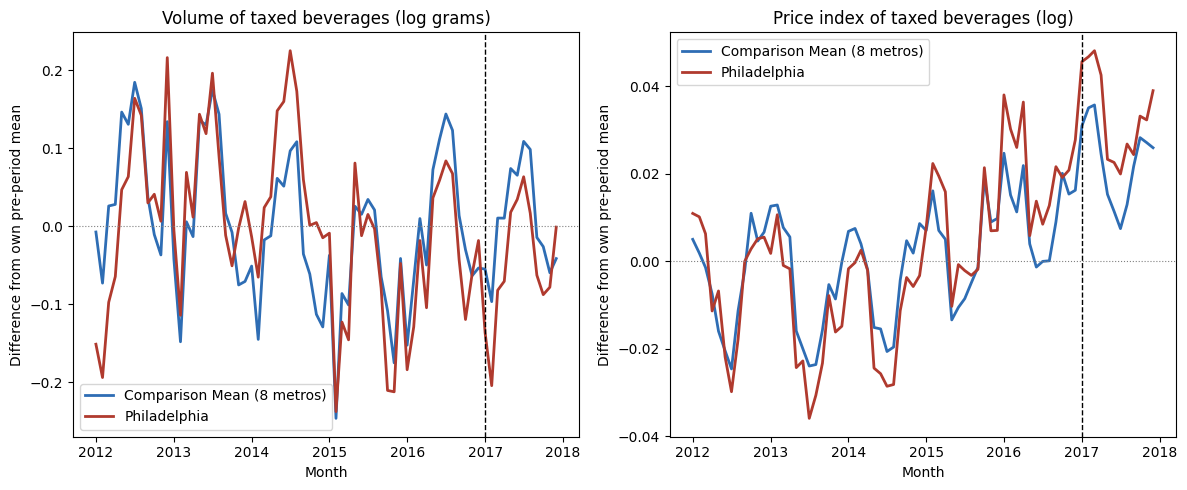

In [21]:
# --- Figure 1: mean outcome by month, Philadelphia against the comparison metros ---

# Calculate the pre mean for each metro to center them at 0
normalized_df = panel_df.copy()
for col in ["log_grams", "log_price"]:
    # Get each metro's average during the pre (post == 0)
    pre_means = panel_df[panel_df["post"] == 0].groupby("metro")[col].mean()
    # Subtract that baseline mean from each metro's values
    normalized_df[col] = panel_df[col] - panel_df["metro"].map(pre_means)

# Group by month and treatment/not
trends = normalized_df.groupby(["month_start", "treated"])[["log_grams", "log_price"]].mean().unstack("treated")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left Panel: Normalized Volume
axes[0].plot(trends.index, trends["log_grams"][0], color="#2E6DB4", lw=2, label="Comparison Mean (8 metros)")
axes[0].plot(trends.index, trends["log_grams"][1], color="#b03a2e", lw=2, label="Philadelphia")
axes[0].axvline(TREAT_DATE, color="black", ls="--", lw=1)
axes[0].axhline(0, color="grey", ls=":", lw=0.8)
axes[0].set_title("Volume of taxed beverages (log grams)")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Difference from own pre-period mean")
axes[0].legend()

# Right Panel: Normalized Price Index
axes[1].plot(trends.index, trends["log_price"][0], color="#2E6DB4", lw=2, label="Comparison Mean (8 metros)")
axes[1].plot(trends.index, trends["log_price"][1], color="#b03a2e", lw=2, label="Philadelphia")
axes[1].axvline(TREAT_DATE, color="black", ls="--", lw=1)
axes[1].axhline(0, color="grey", ls=":", lw=0.8)
axes[1].set_title("Price index of taxed beverages (log)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Difference from own pre-period mean")
axes[1].legend()

plt.tight_layout()
plt.show()

**Key EDA finding (one sentence, with a number this notebook printed):** The taxed beverage volume in Philadelphia fell about 5% (0.055 log points) more than the compared metros in 2017.

**A concern the design will have to handle:** After the changes made in rule 3, there are only 12 post tax months meaning the sample is small and may not be powerful enough to find an effect.

---
## Part 3: Analysis (Milestone 2)

### 3a. The naive estimate

The comparison a client's own analyst would run first. You expect it to be biased; say which way, and why.

In [ ]:
# naive = smf.ols("outcome ~ treatment", data=df).fit(cov_type="HC1")
# print(naive.params["treatment"], naive.bse["treatment"])

**Why the naive estimate is biased, and in which direction:** ___

### 3b. The causal estimate

Keep the one cell that matches your design and delete the other three. Each reports the estimate, its standard
error and the diagnostic its design must pass.

In [ ]:
# --- DiD: two-way fixed effects, standard errors clustered by the unit that was treated ---
# did = smf.ols("outcome ~ treated_post + C(unit) + C(period)", data=df).fit(
#     cov_type="cluster", cov_kwds={"groups": df["unit"]})
# est, se = did.params["treated_post"], did.bse["treated_post"]
#
# Diagnostic, an event study: one coefficient per period relative to treatment, the period before omitted.
# Pre-period coefficients near zero support parallel trends; they cannot prove it.
# es = smf.ols("outcome ~ C(rel_time, Treatment(reference=-1)) + C(unit) + C(period)", data=df).fit(
#     cov_type="cluster", cov_kwds={"groups": df["unit"]})
# With few treated clusters (under about 20), say so and report a wild cluster bootstrap p-value as well.

In [ ]:
# --- IV: two-stage least squares, with the first stage reported ---
# from linearmodels.iv import IV2SLS
# iv = IV2SLS.from_formula("outcome ~ 1 + control_1 + [treatment ~ instrument]", data=df).fit(cov_type="robust")
# est, se = iv.params["treatment"], iv.std_errors["treatment"]
# print(iv.first_stage)          # the first-stage F: below 10 is weak, and the 2SLS interval cannot be trusted
# The estimate is the effect for compliers, the units the instrument moved: say who they are.

In [ ]:
# --- RD: local linear, the bandwidth chosen by rdrobust, the effect at the cutoff ---
# from rdrobust import rdrobust
# from rddensity import rddensity
# rd = rdrobust(y=df["outcome"], x=df["running"], c=CUTOFF)
# est, se = rd.coef.loc["Conventional", "Coeff"], rd.se.loc["Conventional", "Std. Err."]
# print(rd)                      # report the bandwidth with the estimate
# print(rd.ci.loc["Robust"])     # the bias-corrected interval: report this one, beside est
# print(rddensity(X=df["running"].to_numpy(), c=CUTOFF).test)   # manipulation at the cutoff
# rdrobust reports right minus left: if treatment is BELOW the cutoff, use running = CUTOFF - x.

In [ ]:
# --- DML: partially linear model, cross-fitted, five folds (Topic 24, taught Wed 9 Dec: read Chapter 24 ahead) ---
# from doubleml import DoubleMLData, DoubleMLPLR
# from sklearn.ensemble import RandomForestRegressor
# controls = ["control_1", "control_2", "control_3"]
# dml_data = DoubleMLData(df, y_col="outcome", d_cols="treatment", x_cols=controls)
# learner = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE)
# dml = DoubleMLPLR(dml_data, ml_l=learner, ml_m=learner, n_folds=5)
# dml.fit()
# est, se = dml.coef[0], dml.se[0]
# Diagnostic: overlap. If some units are almost certainly treated or untreated given the controls, the
# estimate leans on extrapolation; plot the cross-fitted treatment predictions by treatment group.

In [ ]:
# --- The estimate, its interval and N, in one line the report can quote ---
# ci_low, ci_high = est - 1.96 * se, est + 1.96 * se
# print(f"estimate {est:+.4f} (SE {se:.4f}), 95% CI [{ci_low:+.4f}, {ci_high:+.4f}], N = {len(df):,}")

### 3c. Naive against causal

> The naive estimate is [X]; the causal estimate is [Y]. The gap of [Y - X] is what [the confounder / selection]
> was doing, and its sign matches (or does not match) the direction predicted in 3a.

### 3d. A robustness check that could have overturned the result

The mission asks for at least one check that could have gone the other way. Pick by design:

| Design | A check that can fail |
|---|---|
| DiD | a placebo treatment date in the pre-period; an outcome the policy cannot affect; drop each treated unit in turn |
| IV | a second instrument, alone; the reduced form; an Anderson–Rubin interval if the first stage is weak |
| RD | half and double the bandwidth; a donut that drops the units nearest the cutoff; placebo cutoffs |
| DML | a different learner for the nuisances; a different control set; trimming units with extreme treatment predictions |

For each: what you changed, what you found (the number beside the baseline), and **what it implies** for the claim.

In [ ]:
# --- Robustness: your check here ---

### 3e. Sensitivity bound

How strong would an unobserved confounder have to be to erase the estimate, measured against one you observed?
For a regression-based estimate (DiD, DML's final stage, OLS with controls) the **robustness value** answers it
(Cinelli and Hazlett 2020, *JRSS-B* 82(1)). It is the share of the remaining variance of both the treatment and the
outcome that a confounder would have to explain to bring the estimate to zero. Compare it with the strongest control
you have: if no confounder as strong as that control could erase the estimate, say so; if one could, say that.

For RD and IV the equivalent question is about the design's own assumption: how far would the outcome have to jump
at the cutoff for other reasons, or how large a direct effect of the instrument, to explain the estimate?

In [ ]:
def robustness_value(t_stat, dof, q=1.0):
    """Cinelli and Hazlett's RV_q: the partial R-squared a confounder needs with BOTH treatment and outcome to
    move the estimate by 100*q percent (q = 1 brings it to zero)."""
    f = q * abs(t_stat) / np.sqrt(dof)
    return 0.5 * (np.sqrt(f**4 + 4 * f**2) - f**2)


def partial_r2(t_stat, dof):
    """A regressor's partial R-squared, recovered from its t-statistic."""
    return t_stat**2 / (t_stat**2 + dof)


# The paper's own example (Darfur, t = 4.18 on 783 degrees of freedom) gives RV = 13.9%:
print(f"check against Cinelli and Hazlett's example: RV = {robustness_value(4.18, 783):.1%} (paper: 13.9%)")

# Your estimate, from a regression with your controls (fit.tvalues / fit.df_resid):
# rv = robustness_value(fit.tvalues["treatment"], fit.df_resid)
# Benchmark: your strongest control's partial R-squared with the outcome, and with the treatment.
# out_fit = smf.ols("outcome ~ treatment + control_1 + control_2", data=df).fit()
# trt_fit = smf.ols("treatment ~ control_1 + control_2", data=df).fit()
# bench_y = partial_r2(out_fit.tvalues["control_1"], out_fit.df_resid)
# bench_d = partial_r2(trt_fit.tvalues["control_1"], trt_fit.df_resid)
# print(f"RV = {rv:.1%}; control_1 explains {bench_y:.1%} of the outcome and {bench_d:.1%} of the treatment")

---
## Part 4: Threats to Identification (draft at Milestone 2)

Not "there may be confounding": **which** variable, through **which** path, and **which way** it moves your estimate.
A threat you cannot address is still worth naming. An unnamed one is what the client's analyst will find.

| Threat | Path | Sign of the bias | What I did about it |
|---|---|---|---|
| ___ | ___ → treatment, ___ → outcome | too large / too small / unknown, and why | ___ |
| ___ | ___ | ___ | ___ |
| ___ | ___ | ___ | ___ |

**What I cannot rule out, and what it means for how the client should read the estimate** (an upper bound, a lower
bound, or suggestive only): ___

Milestone 2 asks for at least 500 words across the table and this paragraph.

---
## Part 5: The Streamlit Dashboard

The app must not fit a model. Your deliverable is a causal estimate, a number and a standard error, so write them
to `results.json` here and let the app do arithmetic. The Canvas page **Streamlit Dashboard and Deployment** has
the deployment steps, `requirements.txt`, and every deploy error by its message.

A what-if is an input **the client controls** and an output that is a counterfactual with its interval:
how many units the policy reaches, what it costs, how much hidden bias they are willing to assume. Scaling the
effect beyond the range of treatment in your data is an extrapolation; if your app offers it, the page must say so.

In [ ]:
# --- results.json: everything the app needs, printed by this notebook ---
# results = {
#     "question": "Does [treatment] change [outcome]?",
#     "design": "DiD", "estimand": "effect on the treated",
#     "estimate": float(est), "se": float(se), "n": int(len(df)),
#     "unit": "[outcome units] per [treated unit]",
#     "baseline": float(df.loc[df["treatment"] == 0, "outcome"].mean()),   # continuous treatment: df["outcome"].mean()
#     "robustness_value": float(rv),
# }
# with open("results.json", "w") as f:
#     json.dump(results, f, indent=1)
# print(json.dumps(results, indent=1))

In [ ]:
app_py = """
import json

import numpy as np
import plotly.graph_objects as go
import streamlit as st

r = json.load(open("results.json"))
st.set_page_config(page_title="Consulting Report", layout="wide")
st.title(r["question"])
st.caption(f"{r['design']}, {r['estimand']}, N = {r['n']:,}")

st.sidebar.header("Your scenario")
reach = st.sidebar.number_input("Units the policy would reach", min_value=1, value=100, step=10)
cost = st.sidebar.number_input("Cost per unit reached", min_value=0.0, value=0.0, step=1.0)
bias = st.sidebar.slider("Hidden bias you are willing to assume (share of the estimate)", -1.0, 1.0, 0.0, 0.05,
                         help="0 trusts the design. 0.5 assumes half the estimate is confounding.")

est = r["estimate"] * (1 - bias)
se = r["se"]
total, total_lo, total_hi = est * reach, (est - 1.96 * se) * reach, (est + 1.96 * se) * reach

c1, c2, c3 = st.columns(3)
c1.metric("Effect per unit", f"{est:+.3f}", help=r["unit"])
c2.metric("Total effect, 95% CI", f"{total:+,.1f}", f"[{total_lo:+,.1f}, {total_hi:+,.1f}]", delta_color="off")
c3.metric("Total cost", f"{cost * reach:,.0f}")

st.markdown(f"If the policy reaches **{reach:,}** units, the estimated total change is **{total:+,.1f}** "
            f"(95% CI {total_lo:+,.1f} to {total_hi:+,.1f}), assuming {bias:.0%} of the estimate is hidden bias.")

grid = np.linspace(-1, 1, 81)
mid = r["estimate"] * (1 - grid)
fig = go.Figure()
fig.add_trace(go.Scatter(x=grid, y=mid + 1.96 * se, mode="lines", line=dict(width=0), showlegend=False))
fig.add_trace(go.Scatter(x=grid, y=mid - 1.96 * se, mode="lines", line=dict(width=0), fill="tonexty",
                         fillcolor="rgba(46,109,180,0.2)", name="95% CI"))
fig.add_trace(go.Scatter(x=grid, y=mid, mode="lines", line=dict(color="#2E6DB4"), name="Effect per unit"))
fig.add_hline(y=0, line_dash="dot", line_color="grey")
fig.add_vline(x=bias, line_dash="dash", line_color="#b03a2e")
fig.update_layout(xaxis_title="Assumed hidden bias (share of the estimate)", yaxis_title=r["unit"],
                  template="plotly_white")
st.plotly_chart(fig)
"""

# Uncomment to write it, then commit app.py, results.json and requirements.txt to your repository:
# with open("app.py", "w") as f:
#     f.write(app_py)
print("app.py template ready: uncomment the two lines above to write it.")

**The `.py` module.** The repository needs a module, not only notebooks. Move the functions you call more than once
(loading and cleaning, the estimate, the robustness check) into `src/analysis.py`, import them here, and let the
README name the one command that reproduces `results.json`.

---
## Part 6: The Five-Minute Video

Exactly three things. Five minutes is a ceiling, not a target.

| | What it is | Yours |
|---|---|---|
| **One visual** | the figure that makes the causal claim believable (Figure 1 or the event study, usually) | ___ |
| **One causal claim** | the estimate, its unit and interval, and the assumption under it, in one sentence | ___ |
| **One recommendation** | what the client should do, and what they should still do at the bottom of the interval | ___ |

### Prepare for the public Q&A

Classmates will open GitHub Issues on your repository. Write your answers to these before they ask:

| They will ask | Your answer |
|---|---|
| "How do you know this is causal?" | ___ |
| "What is the strongest threat, and which way does it bias you?" | ___ |
| "Would this hold for a different population or time?" | ___ |
| "Is the effect big enough to act on?" | ___ |

---
## Part 7: AI Methodology Appendix (P.R.I.M.E.)

At least three entries, each through the five steps: **P**rep, **R**equest, **I**terate, **M**echanism Check,
**E**valuate. Hand it in as a PDF with the report.

### Entry 1: [task]

- **Prep:** what you needed, and what you knew before you asked
- **Request:** the exact prompt
- **Iterate:** what came back, and what you changed or asked again
- **Mechanism Check:** how you verified it: a test you ran, a number you reproduced, a source you checked
- **Evaluate:** what you accepted, what you rejected, and why

### Entry 2: [task]

- **Prep:** ___
- **Request:** ___
- **Iterate:** ___
- **Mechanism Check:** ___
- **Evaluate:** ___

### Entry 3: [task]

- **Prep:** ___
- **Request:** ___
- **Iterate:** ___
- **Mechanism Check:** ___
- **Evaluate:** ___

> Graded on judgment, not volume. One entry where the model was wrong and you caught it at the Mechanism Check is
> worth more than three where you pasted and moved on.